# Transition-case prevalence analysis

Question: is the **middle hyperedge-bias case** more prevalent in a high-homogeneity dataset (`email-Eu-full`)?

This notebook simulates HMRW-style walks and, at each step, counts how many candidate hyperedges fall into:

- first case: same previous hyperedge (`e' == e_prev`)
- middle case: shares another node with previous hyperedge (excluding current node)
- third case: neither of the above

Counts are aggregated across all start nodes and all walks.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (
    hyperedge_homogeneity_list,
    hypergraph_disjointness,
    load_txt,
    analyze_transition_cases_with_selection,
    theoretical_case_values,
    empirical_availability_values,
)

## Disjointness vs Availability

In [132]:
# Dataset list (the two datasets used above).
dataset_names = ["contact-primary", "contact-high", "email-Enron-full", "email-Eu-full"]
# dataset_names += ["NDC-classes-full", "NDC-substances-full"]

datasets = {}
for i, name in enumerate(dataset_names):
    print(name)
    data_path = Path(f"../www21-hyperlap-master/dataset/{name}_graph.txt")
    H = load_txt(data_path)
    empirical = empirical_availability_values(H, seed=42 + i)
    theoretical = theoretical_case_values(H)
    homogeneity = hyperedge_homogeneity_list(H)
    disjointness = hypergraph_disjointness(H)

    datasets[name] = {
        "H": H,
        "empirical": empirical,
        "theoretical": theoretical,
        "homogeneity_mean": float(np.mean(homogeneity)),
        "homogeneity": homogeneity,
        "disjointness": disjointness,
    }

contact-primary
contact-high
email-Enron-full
email-Eu-full


Saved: results/images/real_transitions.png


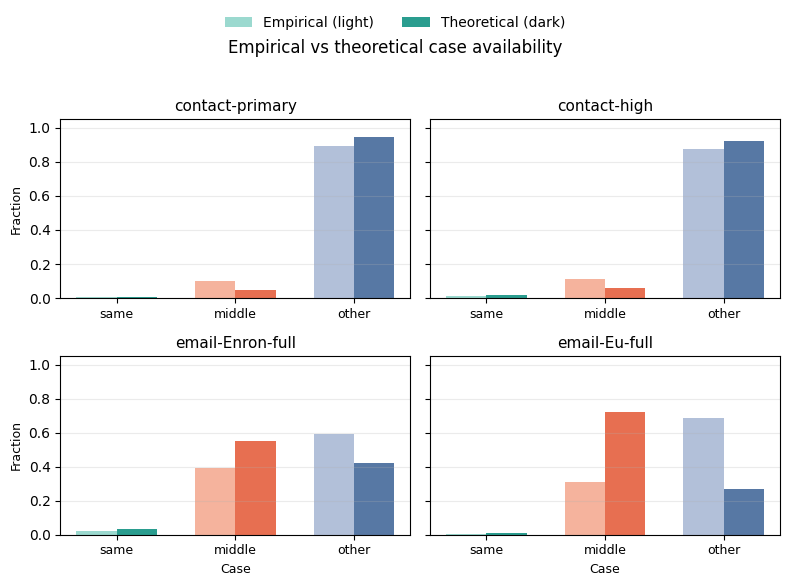

In [ ]:
case_labels = ["same", "middle", "other"]
emp_colors = ["#9bd9cf", "#f5b39d", "#b2c0d9"]
theo_colors = ["#2a9d8f", "#e76f51", "#5778a4"]

fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharey=True)
axes = axes.flatten()

bar_w = 0.34
x = np.arange(len(case_labels), dtype=float)

for ax, name in zip(axes, dataset_names):
    values = datasets[name]
    empirical = np.asarray(values["empirical"], dtype=float)
    theoretical = np.asarray(values["theoretical"], dtype=float)
    dj = values["disjointness"] * 100
    hom = values["homogeneity_mean"]

    for i, _case in enumerate(case_labels):
        ax.bar(x[i] - bar_w / 2, empirical[i], width=bar_w, color=emp_colors[i])
        ax.bar(x[i] + bar_w / 2, theoretical[i], width=bar_w, color=theo_colors[i])

    ax.set_xticks(x)
    ax.set_xticklabels(case_labels, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.set_title(f"{name}", fontsize=11)

for ax in axes[2:]:
    ax.set_xlabel("Case", fontsize=9)
for ax in axes[::2]:
    ax.set_ylabel("Fraction", fontsize=9)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=emp_colors[0], label="Empirical (light)"),
    Patch(facecolor=theo_colors[0], label="Theoretical (dark)"),
]
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.98), ncol=2, frameon=False)

fig.suptitle("Empirical vs theoretical case availability", fontsize=12, y=0.92)
plt.tight_layout(rect=[0, 0, 1, 0.90])

out_dir = Path("results/images")
out_path = out_dir / "real_transitions.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight", pad_inches=0.25)
print(f"Saved: {out_path}")

plt.show()

In [172]:
for name in dataset_names:
    print(f"{name} {datasets[name]['disjointness']:5f}")

contact-primary 0.000796
contact-high 0.000739
email-Enron-full 0.016270
email-Eu-full 0.004083
